# Chuẩn bị dữ liệu và EDA: Amazon Reviews 2023, danh mục Video_Games

Notebook này thay cho bản chạy trên Digital Music 5-core (2018). Những điểm khác so với bản cũ:

1. Dùng Amazon Reviews 2023: timestamp ở mức mili-giây nên chia train/valid/test theo thời gian không còn bị hòa ngày.
2. Đọc file review theo luồng (không nạp cả file vào RAM), lọc k-core trên id đã mã hóa, tăng k tự động cho đến khi tập dữ liệu không vượt `MAX_REVIEWS`.
3. Tiêu đề tự sinh của Amazon (kiểu "Five Stars") được tách ra khỏi cột `title`, vì chúng làm lộ số sao vào văn bản chấm sentiment. Bản gốc được giữ ở `title_raw`.
4. Kết quả ghi vào thư mục riêng `data/processed/Video_Games/`, không ghi đè dữ liệu Digital Music.
5. Ghi thêm `dataset_meta.json` (cấu hình + thống kê) để truy vết kết quả sau này.

Thứ tự chạy: cell cấu hình, tải/đọc dữ liệu, lọc k-core, nạp văn bản, làm sạch, chia tập, EDA.

In [13]:
import sys, gzip, json, re, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd

try:
    import truststore; truststore.inject_into_ssl()
except ImportError:
    pass
try:
    import orjson
    loads = orjson.loads
except ImportError:
    loads = json.loads

sys.path.append("..")
from src.split import leave_one_out

# ---------------- Cấu hình ----------------
CATEGORY = "Video_Games"
URL = ("https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/"
       f"review_categories/{CATEGORY}.jsonl.gz")
CORE_START = 5          # bắt đầu từ 5-core
CORE_MAX = 30           # không tăng k quá giá trị này
MAX_REVIEWS = 300_000   # chấm sentiment bằng transformer tốn thời gian theo số review; chỉnh theo máy của bạn
TIE_WARN = 0.01         # cảnh báo nếu hơn 1% user có 2 review cuối trùng timestamp

ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "data" / "processed" / CATEGORY      # thư mục riêng, không ghi đè Digital Music
SPLIT_DIR = OUT_DIR / "splits"
for d in (RAW_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)
RAW = RAW_DIR / f"{CATEGORY}.jsonl.gz"
CACHE = OUT_DIR / "_pass1_cache.pkl"                   # lưu kết quả đọc lượt 1 để chạy lại nhanh

## 1. Tải file review

File review của cả danh mục khá lớn nên chỉ tải khi chưa có. Nếu mạng hạn chế, tải tay từ link trong `URL` rồi đặt vào `data/raw/`.

In [14]:
if not RAW.exists():
    print("Đang tải:", URL)
    urllib.request.urlretrieve(URL, RAW)
print(RAW.name, f"{RAW.stat().st_size / 1e9:.2f} GB")

Video_Games.jsonl.gz 0.81 GB


## 2. Lượt đọc 1: chỉ lấy id, số sao, thời gian

Mỗi user và item được mã hóa thành số nguyên ngay khi đọc để tiết kiệm bộ nhớ. Văn bản chưa được lấy ở bước này vì ta chưa biết review nào sẽ được giữ lại sau khi lọc k-core.

Trường thời gian trong file raw có thể tên `timestamp` hoặc `sort_timestamp` (tài liệu của dataset ghi cả hai). Code tự dò và in ra tên đã dùng.

In [15]:
def iter_reviews(path):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            yield loads(line)

def ts_of(rec):
    t = rec.get("timestamp")
    return t if t is not None else rec.get("sort_timestamp")

if CACHE.exists():
    c = pd.read_pickle(CACHE)
    umap, imap, p1, ts_field = c["umap"], c["imap"], c["p1"], c["ts_field"]
    print("Đã nạp cache lượt 1:", len(p1), "dòng")
else:
    t0 = time.time()
    umap, imap = {}, {}
    U, I, R, T = [], [], [], []
    ts_field = None
    for n, rec in enumerate(iter_reviews(RAW), 1):
        if ts_field is None:
            ts_field = "timestamp" if rec.get("timestamp") is not None else "sort_timestamp"
        U.append(umap.setdefault(rec["user_id"], len(umap)))
        I.append(imap.setdefault(rec["parent_asin"], len(imap)))
        R.append(rec["rating"])
        T.append(ts_of(rec))
        if n % 1_000_000 == 0:
            print(f"  {n:,} dòng, {time.time() - t0:.0f}s", flush=True)
    p1 = pd.DataFrame({"u": np.asarray(U, dtype=np.int32), "i": np.asarray(I, dtype=np.int32),
                       "rating": np.asarray(R, dtype=np.float32), "ts": np.asarray(T, dtype=np.int64)})
    pd.to_pickle({"umap": umap, "imap": imap, "p1": p1, "ts_field": ts_field}, CACHE)
    print(f"Xong lượt 1: {len(p1):,} dòng, {time.time() - t0:.0f}s")

print("trường thời gian dùng:", ts_field)
print("khoảng giá trị ts:", p1.ts.min(), "->", p1.ts.max(),
      "| ước lượng đơn vị:", "mili-giây" if p1.ts.max() > 1e11 else "giây")
print("user:", p1.u.nunique(), "| item:", p1.i.nunique())

Đã nạp cache lượt 1: 4624615 dòng
trường thời gian dùng: timestamp
khoảng giá trị ts: 911332729000 -> 1694509355529 | ước lượng đơn vị: mili-giây
user: 2766656 | item: 137249


## 3. Bỏ trùng và lọc k-core

- Một user có thể review nhiều lần cùng một `parent_asin` (các biến thể khác nhau của sản phẩm); giữ review mới nhất, như bản cũ.
- Lọc k-core lặp đến khi ổn định, rồi tăng k cho đến khi số review không vượt `MAX_REVIEWS`. Cách này giữ nguyên cấu trúc dữ liệu (mọi user và item đều đủ tương tác), khác với lấy mẫu ngẫu nhiên user vốn làm item bị rớt dưới ngưỡng và làm dữ liệu thưa đi.

In [16]:
p = p1.sort_values("ts", kind="stable").drop_duplicates(["u", "i"], keep="last").reset_index(drop=True)
print(f"Sau bỏ trùng: {len(p):,} (bỏ {len(p1) - len(p):,} dòng trùng user-item)")

def kcore_mask(u, i, k):
    keep = np.ones(len(u), dtype=bool)
    nu, ni = u.max() + 1, i.max() + 1
    while True:
        cu = np.bincount(u[keep], minlength=nu)
        ci = np.bincount(i[keep], minlength=ni)
        new = keep & (cu[u] >= k) & (ci[i] >= k)
        if new.sum() == keep.sum():
            return new
        keep = new

u_arr, i_arr = p.u.to_numpy(), p.i.to_numpy()
rows, chosen_k, chosen_mask = [], None, None
last_k, last_mask = None, None          # core không rỗng lớn nhất đã gặp (dự phòng)
for k in range(CORE_START, CORE_MAX + 1):
    m = kcore_mask(u_arr, i_arr, k)
    n_rev = int(m.sum())
    rows.append({"k": k, "user": int(np.unique(u_arr[m]).size), "item": int(np.unique(i_arr[m]).size),
                 "review": n_rev})
    if n_rev == 0:
        break                            # core rỗng, các k lớn hơn cũng rỗng
    last_k, last_mask = k, m
    if chosen_k is None and n_rev <= MAX_REVIEWS:
        chosen_k, chosen_mask = k, m
    if chosen_k is not None and k >= chosen_k + 2:
        break                            # in thêm vài dòng để xem xu hướng, rồi dừng
core_table = pd.DataFrame(rows)
display(core_table)

if chosen_k is None:                     # không k nào đạt MAX_REVIEWS
    assert last_k is not None, "Không còn review nào sau khi lọc: kiểm tra lại dữ liệu raw."
    chosen_k, chosen_mask = last_k, last_mask
    print(f"CẢNH BÁO: ngay cả {chosen_k}-core vẫn có {int(chosen_mask.sum()):,} review > MAX_REVIEWS={MAX_REVIEWS:,}. "
          "Đang dùng core lớn nhất còn dữ liệu; hãy tăng MAX_REVIEWS hoặc CORE_MAX.")
print(f"Chọn {chosen_k}-core: {int(chosen_mask.sum()):,} review")
sel = p[chosen_mask].reset_index(drop=True)

Sau bỏ trùng: 4,555,500 (bỏ 69,115 dòng trùng user-item)


,k,user,item,review
0,5,94762,25612,814586
1,6,58987,18619,606449
2,7,37990,13286,452940
3,8,24906,9450,338500
4,9,16886,7064,257475
5,10,11658,5335,196508
6,11,8196,4061,150396


Chọn 9-core: 257,475 review


## 4. Lượt đọc 2: nạp tiêu đề và nội dung cho các cặp user-item đã chọn

Đọc lại file một lần nữa, chỉ giữ dòng thuộc tập đã chọn. Kết quả được đối chiếu với lượt 1 để chắc chắn không lệch dòng.

In [17]:
n_items = len(imap)
pair_key = lambda u, i: int(u) * n_items + int(i)
wanted = set((sel.u.astype(np.int64) * n_items + sel.i.astype(np.int64)).tolist())

t0 = time.time()
keep = []
for rec in iter_reviews(RAW):
    u, i = umap.get(rec["user_id"]), imap.get(rec["parent_asin"])
    if u is not None and i is not None and pair_key(u, i) in wanted:
        keep.append((u, i, rec["rating"], ts_of(rec), rec.get("title") or "", rec.get("text") or ""))
print(f"Xong lượt 2: {len(keep):,} dòng, {time.time() - t0:.0f}s")

df = pd.DataFrame(keep, columns=["u", "i", "rating", "timestamp", "title_raw", "text"])
df = df.sort_values("timestamp", kind="stable").drop_duplicates(["u", "i"], keep="last")
assert len(df) == len(sel), f"Lệch giữa hai lượt đọc: {len(df)} vs {len(sel)}"

inv_u = {v: k for k, v in umap.items()}
inv_i = {v: k for k, v in imap.items()}
df["user_id"] = df.u.map(inv_u)
df["parent_asin"] = df.i.map(inv_i)
df = df.drop(columns=["u", "i"])

Xong lượt 2: 263,921 dòng, 42s


## 5. Làm sạch tiêu đề tự sinh

Khi user không viết tiêu đề, Amazon điền sẵn "Five Stars", "One Star"... Chuỗi này chứa trực tiếp số sao, nên nếu ghép vào văn bản đưa cho mô hình sentiment thì điểm sentiment bị lẫn thông tin của nhãn sao. Ở đây:

- `title_raw`: tiêu đề gốc.
- `title`: tiêu đề sau khi đã bỏ phần tự sinh (để trống nếu là tiêu đề tự sinh). Các bước chấm sentiment phía sau chỉ nên đọc cột này.

In [18]:
AUTO_TITLE = re.compile(r"^\s*(one|two|three|four|five|[1-5](\.0)?)\s*[- ]?stars?\s*[.!]*\s*$", re.IGNORECASE)

df["title_auto"] = df.title_raw.str.match(AUTO_TITLE)
df["title"] = np.where(df.title_auto, "", df.title_raw)
df["n_words"] = df.text.str.split().str.len().fillna(0).astype(int)
df["has_text"] = df.n_words > 0

print("tiêu đề tự sinh:", round(df.title_auto.mean(), 3))
print(df[df.title_auto].title_raw.value_counts().head(6).to_dict())
print("review không có chữ trong nội dung:", round((~df.has_text).mean(), 3))
print("review không có cả nội dung lẫn tiêu đề tự viết:", round(((~df.has_text) & (df.title == "")).mean(), 3))

tiêu đề tự sinh: 0.189
{'Five Stars': 39024, 'Four Stars': 5429, 'Three Stars': 2342, 'One Star': 935, 'Two Stars': 653, '5 stars': 51}
review không có chữ trong nội dung: 0.0
review không có cả nội dung lẫn tiêu đề tự viết: 0.0


## 6. Chia train/valid/test theo thời gian

Với timestamp mili-giây, hòa thời gian hiếm hơn nhiều so với bản 2018. Vẫn đo tỉ lệ hòa ở hai review cuối và, nếu còn hòa, phá hòa theo `parent_asin` để kết quả chia luôn giống nhau giữa các lần chạy (không phụ thuộc thứ tự dòng trong file).

In [19]:
df = df.sort_values(["user_id", "timestamp", "parent_asin"], kind="stable").reset_index(drop=True)

last2 = df.groupby("user_id").timestamp.apply(lambda s: s.iloc[-1] == s.iloc[-2])
tie_rate = float(last2.mean())
print(f"tỉ lệ user có 2 review cuối trùng timestamp: {tie_rate:.4f}")
if tie_rate > TIE_WARN:
    print("CẢNH BÁO: tỉ lệ hòa cao, cần xem lại cách chia (ví dụ chia theo phiên hoặc theo ngày).")

train, valid, test = leave_one_out(df)
for name, d in [("train", train), ("valid", valid), ("test", test)]:
    d.to_csv(SPLIT_DIR / f"{name}.csv.gz", index=False)

print(f"train={len(train):,} valid={len(valid):,} test={len(test):,}")
print("item đích của test không có trong train:",
      round((~test.parent_asin.isin(train.parent_asin)).mean(), 4),
      "| không có trong train+valid:",
      round((~test.parent_asin.isin(pd.concat([train, valid]).parent_asin)).mean(), 4))
print("item đích của valid không có trong train:",
      round((~valid.parent_asin.isin(train.parent_asin)).mean(), 4))

tỉ lệ user có 2 review cuối trùng timestamp: 0.0001
train=223,703 valid=16,886 test=16,886
item đích của test không có trong train: 0.0017 | không có trong train+valid: 0.0
item đích của valid không có trong train: 0.0008


In [20]:
out_cols = ["user_id", "parent_asin", "rating", "title", "title_raw", "text", "timestamp"]
df[out_cols].to_csv(OUT_DIR / f"{CATEGORY}_core.csv.gz", index=False)
print("đã lưu:", OUT_DIR / f"{CATEGORY}_core.csv.gz")

đã lưu: D:\PycharmProjects\Sentiment_fix\data\processed\Video_Games\Video_Games_core.csv.gz


## 7. EDA: dataset này có đủ tốt cho đề tài sentiment không

Bảng dưới so sánh với Digital Music 5-core (2018) mà bạn đã dùng, các số liệu tham chiếu là kết quả đo trước đó trên dữ liệu đó. Hai tiêu chí quan trọng nhất cho đề tài là có đủ review thấp sao và bình luận có đủ chữ để sentiment mang thông tin ngoài số sao.

In [21]:
n_user, n_item, n_rev = df.user_id.nunique(), df.parent_asin.nunique(), len(df)
per_user = df.groupby("user_id").size()
per_item = df.groupby("parent_asin").size()

stats = {
    "k-core": chosen_k,
    "user": n_user, "item": n_item, "review": n_rev,
    "mật độ": n_rev / (n_user * n_item),
    "lịch sử user (trung vị)": float(per_user.median()),
    "review mỗi item (trung vị)": float(per_item.median()),
    "tỉ lệ review 5 sao": float((df.rating == 5).mean()),
    "tỉ lệ review <= 2 sao": float((df.rating <= 2).mean()),
    "tỉ lệ review <= 3 sao": float((df.rating <= 3).mean()),
    "số từ nội dung (trung vị)": float(df.n_words.median()),
    "tỉ lệ review >= 20 từ": float((df.n_words >= 20).mean()),
    "tỉ lệ tiêu đề tự sinh": float(df.title_auto.mean()),
    "tỉ lệ user chỉ cho toàn 5 sao": float((df.groupby("user_id").rating.min() == 5).mean()),
    "tỉ lệ user có 2 review cuối trùng timestamp": tie_rate,
}
ref = {  # Digital Music 5-core (2018), đã đo ở lần phân tích trước
    "k-core": 5, "user": 12381, "item": 9906, "review": 123518,
    "mật độ": 0.001007, "lịch sử user (trung vị)": 7.0, "review mỗi item (trung vị)": 8.0,
    "tỉ lệ review 5 sao": 0.795, "tỉ lệ review <= 2 sao": 0.023, "tỉ lệ review <= 3 sao": 0.066,
    "số từ nội dung (trung vị)": 10.0, "tỉ lệ review >= 20 từ": 0.407,
    "tỉ lệ tiêu đề tự sinh": 0.408, "tỉ lệ user chỉ cho toàn 5 sao": 0.509,
    "tỉ lệ user có 2 review cuối trùng timestamp": 0.516,
}
cmp = pd.DataFrame({"Video_Games": stats, "Digital Music (2018)": ref})
display(cmp.map(lambda x: f"{x:,.4f}" if isinstance(x, float) and abs(x) < 10 else f"{x:,.1f}" if isinstance(x, float) else f"{x:,}"))

,Video_Games,Digital Music (2018)
k-core,9.0000,5.0000
user,"16,886.0","12,381.0"
item,"7,064.0","9,906.0"
review,"257,475.0","123,518.0"
mật độ,0.0022,0.0010
lịch sử user (trung vị),12.0,7.0000
review mỗi item (trung vị),19.0,8.0000
tỉ lệ review 5 sao,0.6346,0.7950
tỉ lệ review <= 2 sao,0.0974,0.0230
tỉ lệ review <= 3 sao,0.1893,0.0660


In [22]:
print("Phân bố số sao:")
print(df.rating.value_counts(normalize=True).sort_index().round(3).to_string())
print("\nTiêu đề tự sinh theo số sao:")
print(df.groupby("rating").title_auto.mean().round(3).to_string())
print("\nSố từ nội dung theo số sao (trung vị):")
print(df.groupby("rating").n_words.median().to_string())
print("\nPhân vị số từ:", df.n_words.quantile([.1, .25, .5, .75, .9]).to_dict())

Phân bố số sao:
rating
1.0    0.054
2.0    0.043
3.0    0.092
4.0    0.176
5.0    0.635

Tiêu đề tự sinh theo số sao:
rating
1.0    0.068
2.0    0.059
3.0    0.100
4.0    0.120
5.0    0.240

Số từ nội dung theo số sao (trung vị):
rating
1.0     60.0
2.0    101.0
3.0     90.0
4.0     77.0
5.0     23.0

Phân vị số từ: {0.1: 2.0, 0.25: 9.0, 0.5: 36.0, 0.75: 125.0, 0.9: 339.0}


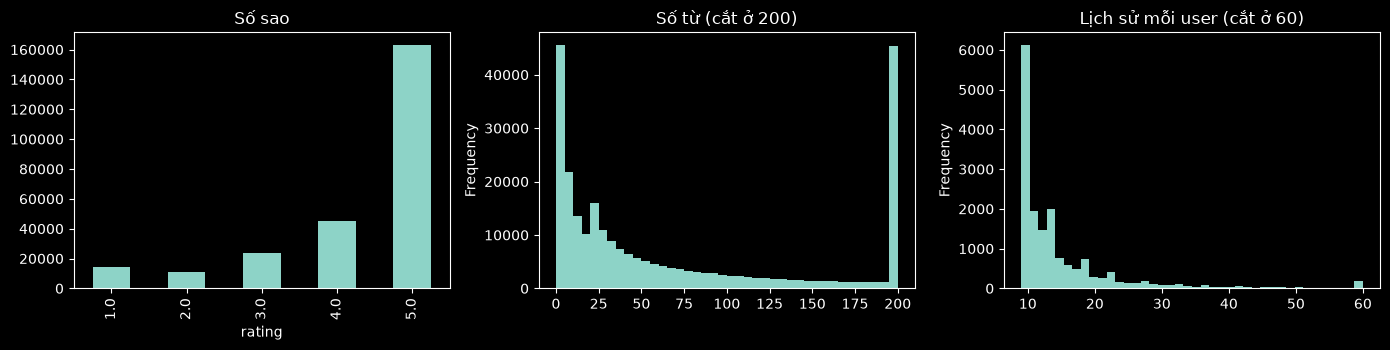

In [23]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    df.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Số sao")
    df.n_words.clip(upper=200).plot.hist(bins=40, ax=ax[1], title="Số từ (cắt ở 200)")
    per_user.clip(upper=60).plot.hist(bins=40, ax=ax[2], title="Lịch sử mỗi user (cắt ở 60)")
    plt.tight_layout(); plt.show()
except ImportError:
    print("Chưa cài matplotlib, bỏ qua biểu đồ.")

## 8. Lưu metadata

File này ghi lại cấu hình và thống kê của lần chạy, để các notebook sau (baseline, ablation) và báo cáo truy vết được kết quả đến từ dữ liệu nào.

In [24]:
meta = {
    "category": CATEGORY, "source_url": URL, "raw_file": RAW.name,
    "timestamp_field": ts_field, "timestamp_unit": "ms" if p1.ts.max() > 1e11 else "s",
    "core_start": CORE_START, "core_chosen": chosen_k, "max_reviews": MAX_REVIEWS,
    "split": "leave-one-out theo timestamp, phá hòa theo parent_asin",
    "auto_title_cleaned": True,
    "n_user": n_user, "n_item": n_item, "n_review": n_rev,
    "n_train": len(train), "n_valid": len(valid), "n_test": len(test),
    "tie_rate_last2": tie_rate,
    "generated_at": pd.Timestamp.now().isoformat(timespec="seconds"),
}
(OUT_DIR / "dataset_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "category": "Video_Games",
  "source_url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Video_Games.jsonl.gz",
  "raw_file": "Video_Games.jsonl.gz",
  "timestamp_field": "timestamp",
  "timestamp_unit": "ms",
  "core_start": 5,
  "core_chosen": 9,
  "max_reviews": 300000,
  "split": "leave-one-out theo timestamp, phá hòa theo parent_asin",
  "auto_title_cleaned": true,
  "n_user": 16886,
  "n_item": 7064,
  "n_review": 257475,
  "n_train": 223703,
  "n_valid": 16886,
  "n_test": 16886,
  "tie_rate_last2": 0.00011844131232974062,
  "generated_at": "2026-10-18T23:22:04"
}
